# Ball-missing and missing-player analysis

Ball coordinates can disappear without the ball actually leaving the phase of play. This notebook treats the disappearance as an observation problem, not as permission to invent an exact ball path.

## Robust interpretation

- Look backward to the last controlled player/team evidence and forward to the first reliable reappearance or control evidence.
- Preserve the prior team during an unresolved gap when the trajectory, receiver path, and post-gap team agree.
- Keep the interval contested when both teams converge, the ball decelerates near pressure, or the next touch is not controlled.
- Treat low motion, out-of-play geometry, restart context, and second-half pre-kickoff as dead-ball evidence—not as fixed-duration labels.
- A missing player near the apparent ball path is handled as uncertainty in the observation, not as a new track identity.

The feature bank exposes these as confidence signals. The decoder decides how much each signal changes H/A/D confidence.

## Observable cases

| Observation pattern | Evidence signal | Conservative interpretation |
|---|---|---|
| Nearby endpoint displacement with coherent direction | `gap_nearby_teleport_candidate` | ball may have been briefly unobserved; do not change team alone |
| Same area and all-player slowdown | `gap_same_area_low_motion_dead_candidate` | dead-ball candidate |
| Path ends at a player and the same team controls after reappearance | `gap_same_team_reappearance_candidate` | retain prior team through the gap |
| Prior team before the gap, opposing team controls after it | `gap_opponent_reappearance_switch_candidate` | provisional switch; require post-gap persistence |
| Receiver accelerates while the ball is missing | `gap_receiver_acceleration_candidate` | likely continuation to that receiver, not an exact path estimate |
| Ball slows in open space, then moves again without a nearby receiver | `gap_pass_to_space_candidate` / `gap_opponent_near_miss_candidate` | keep prior team or contested until control appears |
| Out-of-play or restart context | `gap_out_of_play_dead_candidate`, restart signals | protect D until live control is visible |

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'possession').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from possession.baseline_pipeline import ClosestTeamRuleModel, slot_team_map
from possession.pipeline import build_evidence_table, detect_scenarios
from possession.calculations.plotting import plot_evidence_window, select_ball_gap_event_window
from games import asset_paths

model = ClosestTeamRuleModel()
features = detect_scenarios(build_evidence_table(model=model))
missing = features['ball_x'].isna() | features['ball_y'].isna()
starts = np.flatnonzero(missing.to_numpy() & ~np.r_[False, missing.to_numpy()[:-1]])
ends = np.flatnonzero(missing.to_numpy() & ~np.r_[missing.to_numpy()[1:], False])
episodes = []
signal_columns = [column for column in [
    'gap_nearby_teleport_candidate', 'gap_same_area_low_motion_dead_candidate',
    'gap_same_team_reappearance_candidate', 'gap_opponent_reappearance_switch_candidate',
    'gap_receiver_acceleration_candidate', 'gap_pass_to_space_candidate',
    'gap_opponent_near_miss_candidate', 'gap_out_of_play_dead_candidate',
    'restart_low_motion_cluster_candidate', 'restart_live_control_candidate',
    'second_half_pre_kickoff_dead_candidate', 'gap_same_team_confidence',
    'gap_switch_confidence', 'gap_deadball_confidence', 'gap_pass_to_space_confidence',
] if column in features.columns]
for start, end in zip(starts, ends):
    if start == 0 or end + 1 >= len(features):
        continue
    row = features.iloc[start]
    record = {'start_frame': int(row['frame']), 'end_frame': int(features.iloc[end]['frame']),
              'duration_s': (end - start + 1) / 25.0}
    for column in signal_columns:
        value = features.iloc[start][column]
        record[column] = bool(value) if isinstance(value, (bool, np.bool_)) else value
    episodes.append(record)
episodes = pd.DataFrame(episodes).sort_values(['duration_s', 'start_frame'], ascending=[False, True])
display(episodes.head(25))
print(f'internal missing-ball episodes: {len(episodes)}')

,start_frame,end_frame,duration_s,gap_nearby_teleport_candidate,gap_same_area_low_motion_dead_candidate,gap_same_team_reappearance_candidate,gap_opponent_reappearance_switch_candidate,gap_receiver_acceleration_candidate,gap_pass_to_space_candidate,gap_opponent_near_miss_candidate,gap_out_of_play_dead_candidate,restart_low_motion_cluster_candidate,restart_live_control_candidate,second_half_pre_kickoff_dead_candidate,gap_same_team_confidence,gap_switch_confidence,gap_deadball_confidence,gap_pass_to_space_confidence
148,157546,163082,221.48,False,False,False,True,False,False,False,False,False,False,False,0.0,1.0,0.00,0.0
1,5108,10642,221.40,False,False,False,False,False,False,False,True,False,False,False,0.0,0.0,0.00,0.0
41,58081,61546,138.64,False,False,False,False,False,False,False,True,False,False,False,0.0,0.0,0.00,0.0
68,86615,88351,69.48,False,False,False,False,False,False,False,False,False,False,False,0.0,0.0,0.00,0.0
56,73997,75531,61.40,False,False,False,True,False,False,False,False,False,False,False,0.0,1.0,0.00,0.0
55,72560,73950,55.64,False,False,False,True,False,False,False,True,False,False,False,0.0,1.0,0.00,0.0
30,46678,48030,54.12,False,False,False,True,False,False,False,False,False,False,False,0.0,1.0,0.00,0.0
52,70196,71519,52.96,False,False,False,False,False,False,False,False,False,False,False,0.0,0.0,0.00,0.0
165,175715,176992,51.12,False,False,False,False,False,False,False,False,False,False,False,0.0,0.0,0.00,0.0
158,168918,170177,50.40,False,False,False,True,False,False,False,False,False,False,False,0.0,1.0,0.00,0.0


internal missing-ball episodes: 184


## Case diagrams

Each selected gap is rendered with the shared pitch view above the shared evidence timeline. The timeline is the audit surface: it shows what was observed before, during, and after the gap, while the pitch view shows the player paths and nearby pressure.

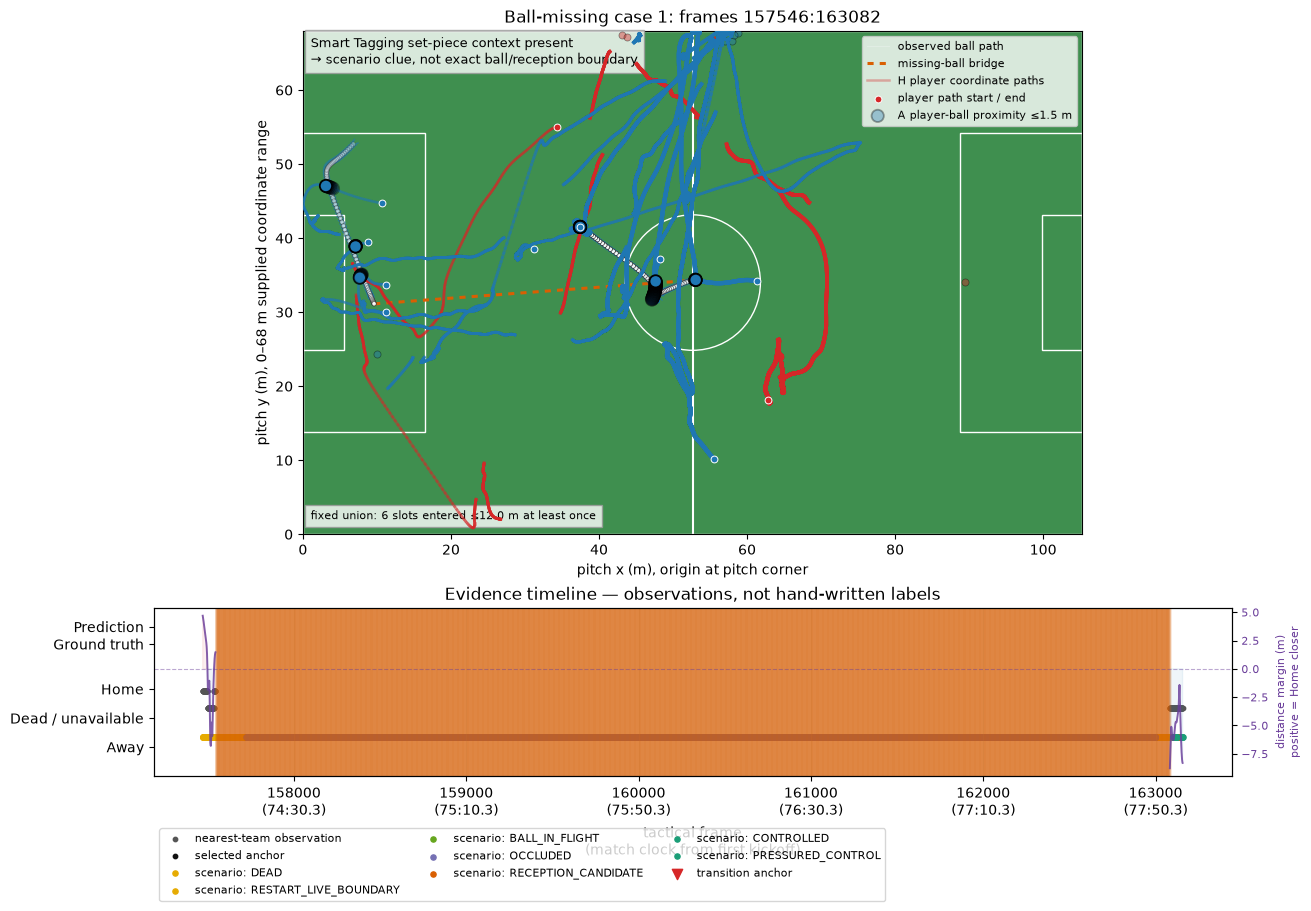

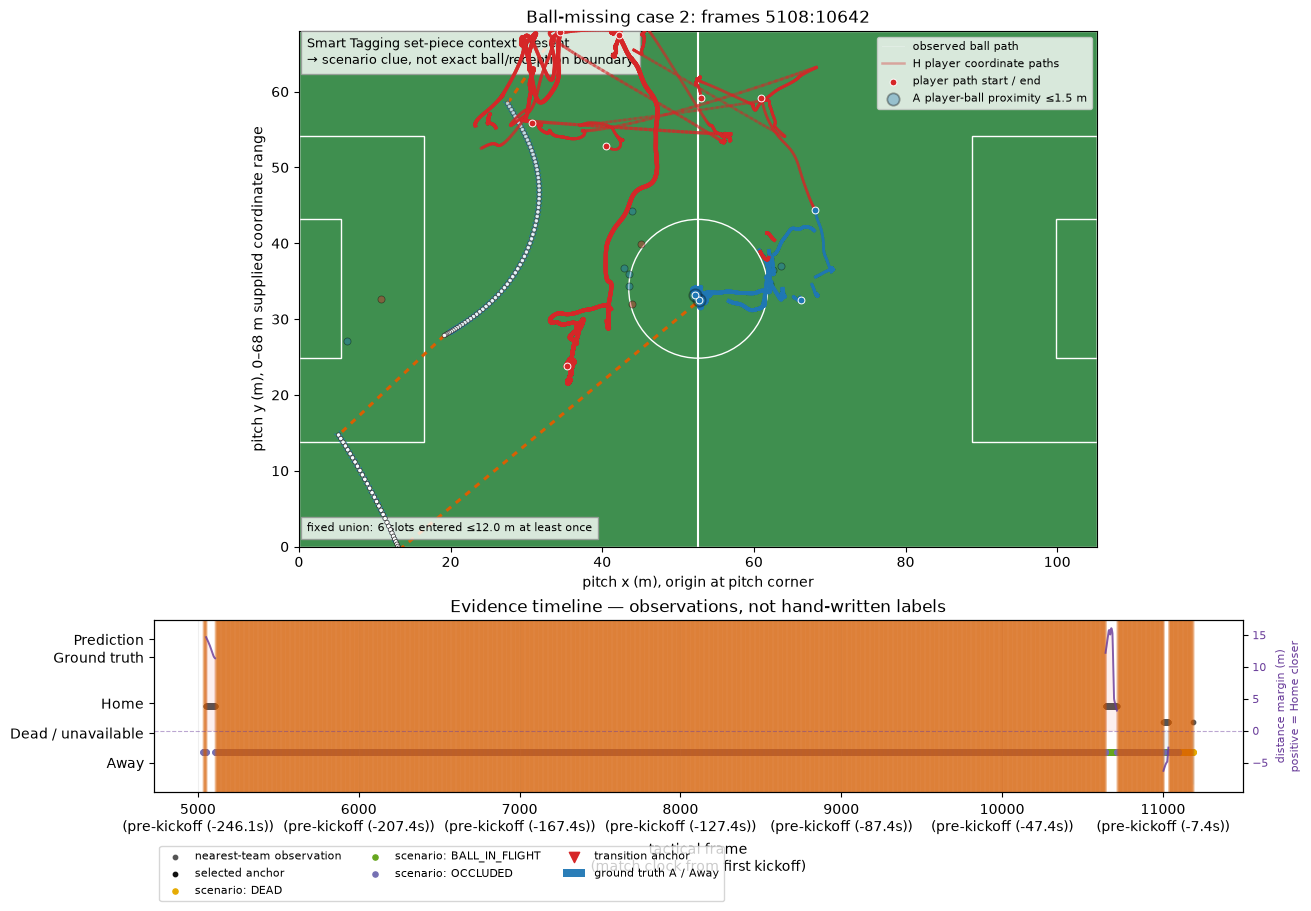

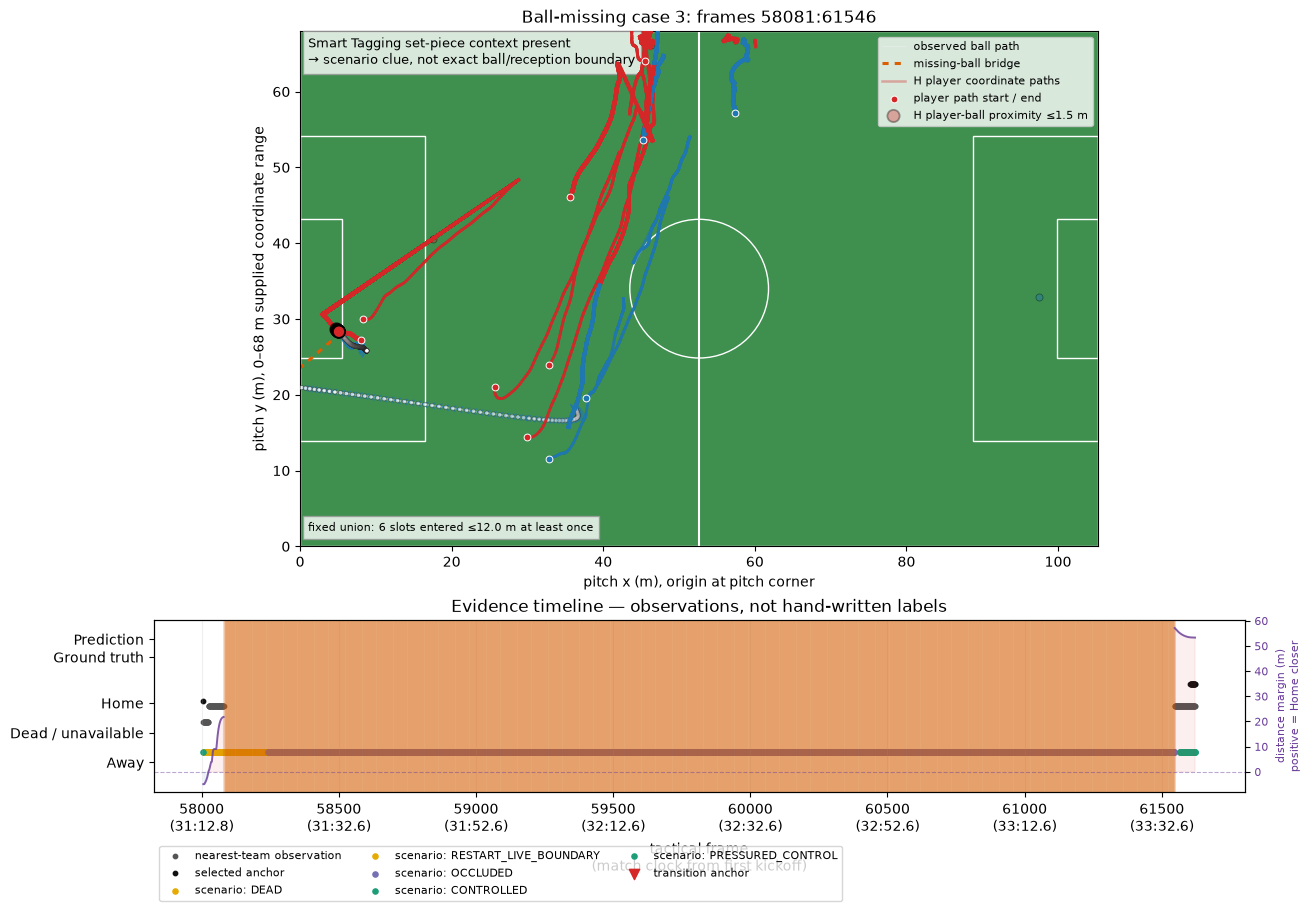

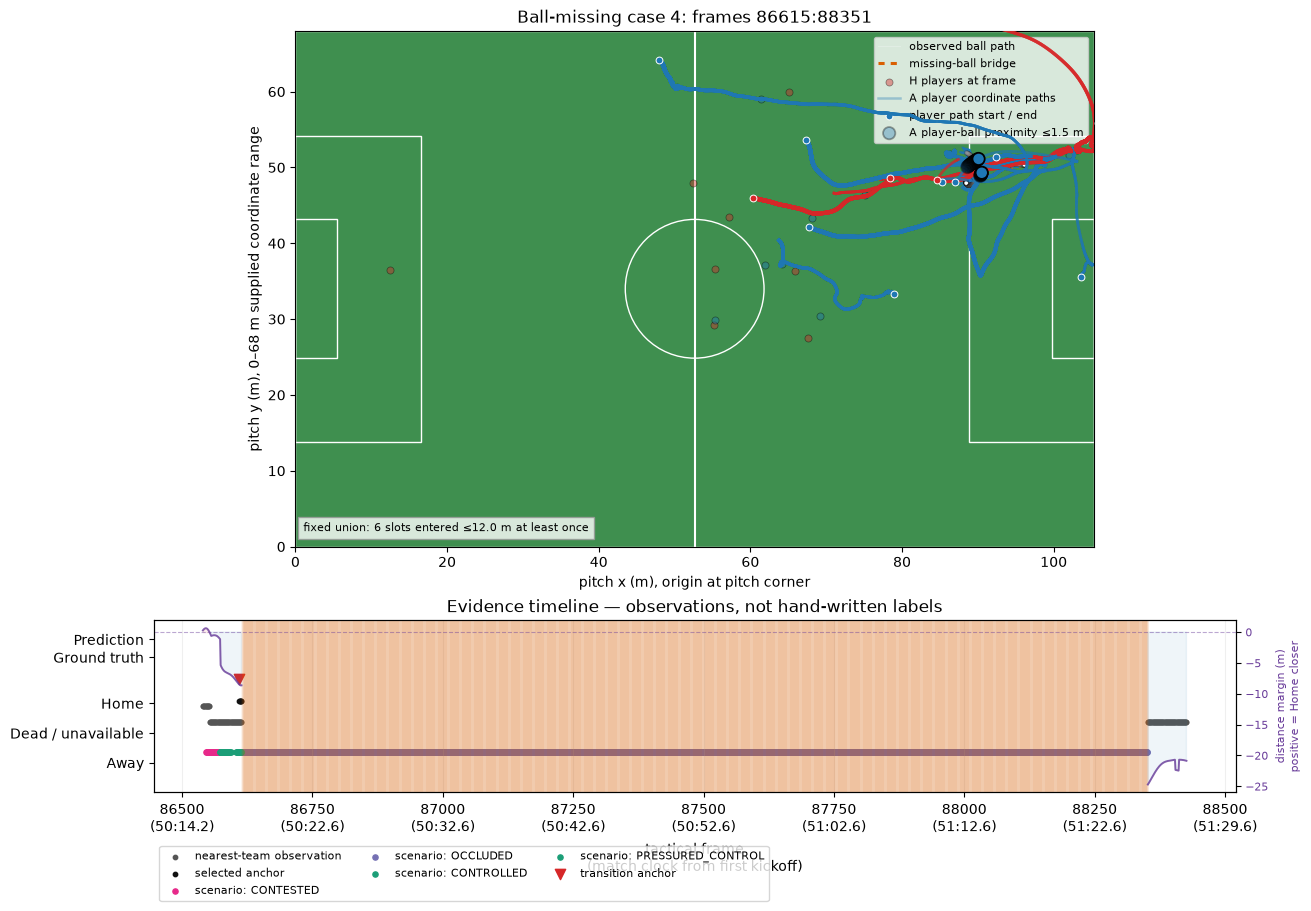

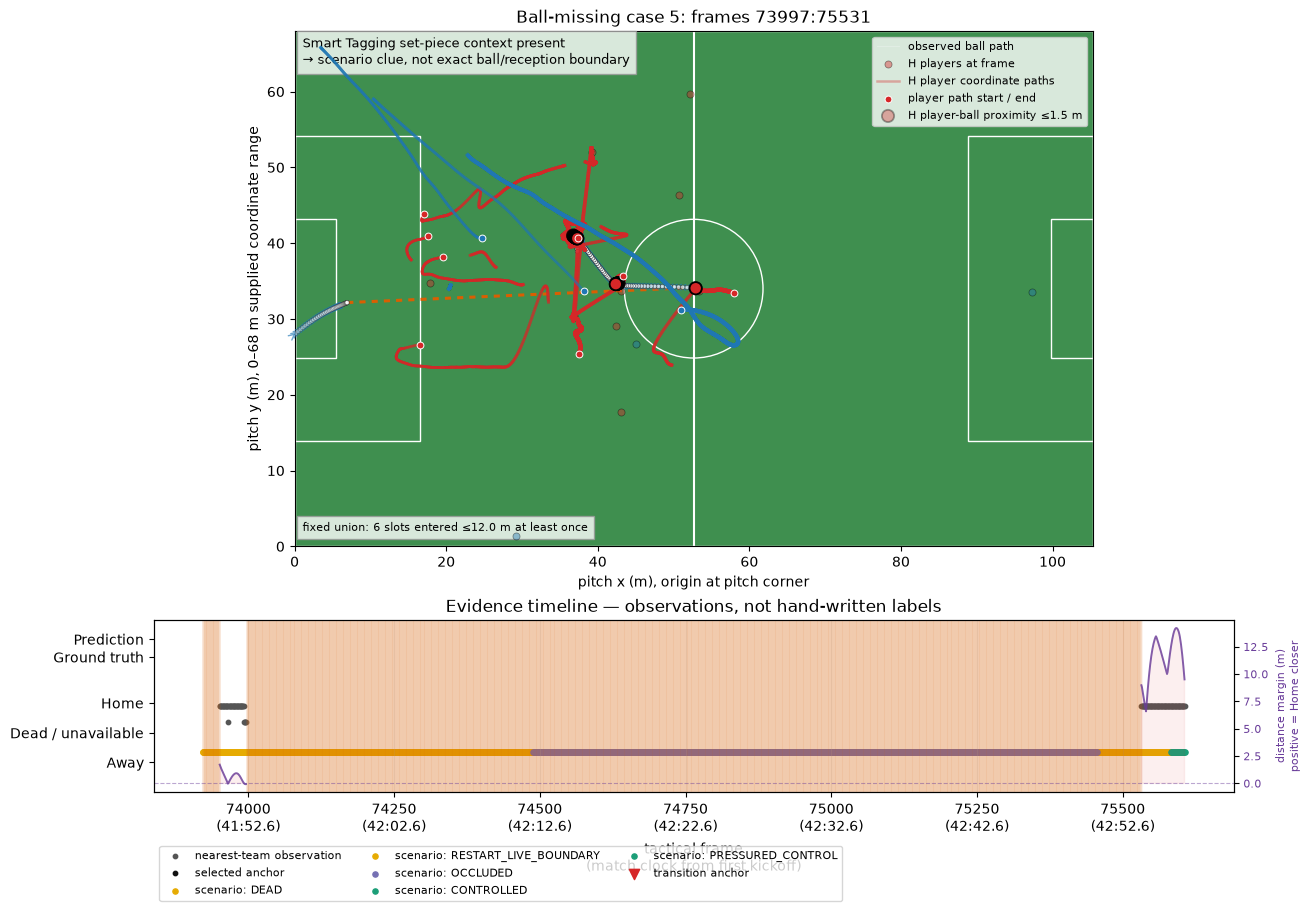

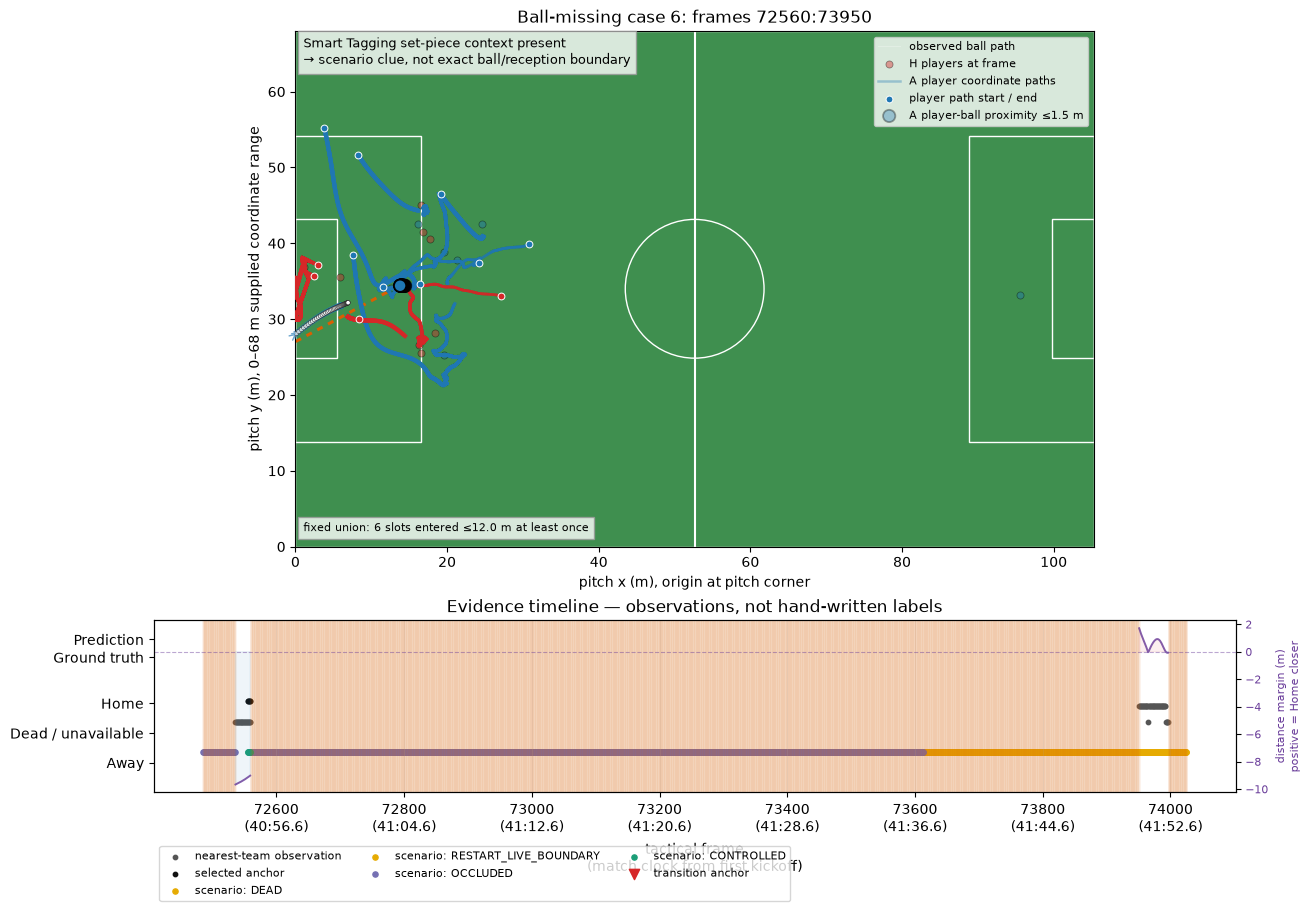

In [2]:
team_by_slot = slot_team_map(asset_paths(model.game, model.data_dir, source='tactical')['atd_meta'])
gt_path = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
gt_by_frame = pd.Series(dtype='string')
if gt_path.exists():
    gt_table = pd.read_csv(gt_path)
    gt_by_frame = gt_table.set_index('frame')['label'].astype(str).str.upper()

for case_number, row in enumerate(episodes.head(6).itertuples(index=False), start=1):
    window = select_ball_gap_event_window(features, (int(row.start_frame), int(row.end_frame)), minimum_context_frames=75)
    fig, axes = plot_evidence_window(
        features, window['start_frame'], window['end_frame'],
        team_by_slot=team_by_slot, ground_truth=gt_by_frame,
    )
    axes[0].set_title(f'Ball-missing case {case_number}: frames {row.start_frame}:{row.end_frame}')
    plt.show()

## Optional George observation layer

### Problem

A missing ball coordinate is not necessarily a change of possession. It may be an occlusion, a broadcast/tactical disagreement, a high ball, or an out-of-play episode. The tactical track alone therefore leaves some gaps with no geometric observation.

### Idea

George's `ballfill` branch supplies an additional, source-aware ball observation: fused tactical/broadcast coordinates, a source (`bc`, `flight`, `agree`, ...), and an estimated positional uncertainty. This is evidence for the gap detector, not a possession label, and it cannot replace anchors or the transition resolver.

### Construction

The optional adapter in [`possession_lab/george_ballfill_adapter.py`](../possession_lab/george_ballfill_adapter.py) preserves `ball_x_tactical`/`ball_y_tactical`, attaches `ball_fill_source`, `ball_fill_sigma_m`, and related probabilities, and fills only eligible tactical gaps. The default experiment accepts observed/fused sources and rejects George's carrier-HMM `filled` source; that source can be enabled only as a separate ablation. The resulting table then follows the shared path: `observations → scenario evidence → anchors → transition/no-switch hypotheses → interval resolver → H/A/D/X`.

### Evaluation result

On the current local `data/ball/BAR-ATH_ball.csv`, the ablation fills 16,140 tactical gaps and changes 7,751 final labels, including 145 public-scored frames. The public result falls to Macro-F1 `0.872314`, Spell-F1 `0.600000`, and Transition F1@25 `0.388889`, versus the reference `0.891747`, `0.620690`, and `0.457143`. George therefore supplies useful additional observations, but this particular fill policy is not safe to promote: it changes the ball trajectory enough to create unsupported scenario/ownership changes. The adapter remains available for source-specific future ablations and private-match auditing.

The reproducible ablation is [`possession_lab/run_george_ballfill_experiment.py`](../possession_lab/run_george_ballfill_experiment.py). It requires a generated `BAR-ATH_ball.csv` from George's branch and writes a separate candidate submission, so the reference model remains unchanged. Enabling the carrier-HMM `filled` source is a separate diagnostic: it filled 30,388 gaps and scored `0.8796 / 0.6069 / 0.4000`, still below the reference, so it remains disabled by default.